In [10]:

import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# Load dataset
df = pd.read_csv(
    "/content/household_power_consumption.txt",
    sep=";", na_values=["?"], low_memory=False
)
# Select numerical features
cols = ["Global_active_power", "Global_reactive_power",
        "Voltage", "Global_intensity", "Sub_metering_1",
        "Sub_metering_2", "Sub_metering_3"]

for c in cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Select 10,000 consecutive records
df = df.iloc[:10000].copy()

# Handle missing values
df[cols] = df[cols].interpolate(
    method="linear", limit_direction="both"
)
df = df.dropna(subset=cols)

# Normalize features
scaler = MinMaxScaler()
data = scaler.fit_transform(df[cols])

print("Dataset loaded and cleaned successfully")
print("Records:", len(df))
print("Missing values:", df[cols].isna().sum().sum())
print("Normalized shape:", data.shape)


Dataset loaded and cleaned successfully
Records: 10000
Missing values: 0
Normalized shape: (10000, 7)


In [12]:

import numpy as np

X, y = [], []

for i in range(60, len(data)):
    X.append(data[i-60:i])
    y.append(data[i, 0])

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)

print("Sequences generated successfully")
print("Input shape:", X.shape)
print("Target shape:", y.shape)


Sequences generated successfully
Input shape: (9940, 60, 7)
Target shape: (9940,)


In [14]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Split data chronologically
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Build LSTM model
model = Sequential([
    LSTM(32, input_shape=(60, 7)),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")

# Train model
model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    verbose=1
)

print("LSTM model trained successfully")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - loss: 0.0042
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.0034
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.0031
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0031
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 0.0030
LSTM model trained successfully
Training records: 7952
Testing records: 1988


In [16]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict unseen test records
pred = model.predict(X_test, verbose=0).ravel()

# Convert normalized values to kW
scale = scaler.scale_[0]
offset = scaler.min_[0]

actual = (y_test - offset) / scale
predicted = (pred - offset) / scale

# Calculate errors
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("MAE:", round(mae, 4), "kW")
print("RMSE:", round(rmse, 4), "kW")


MAE: 0.4888 kW
RMSE: 0.6851 kW


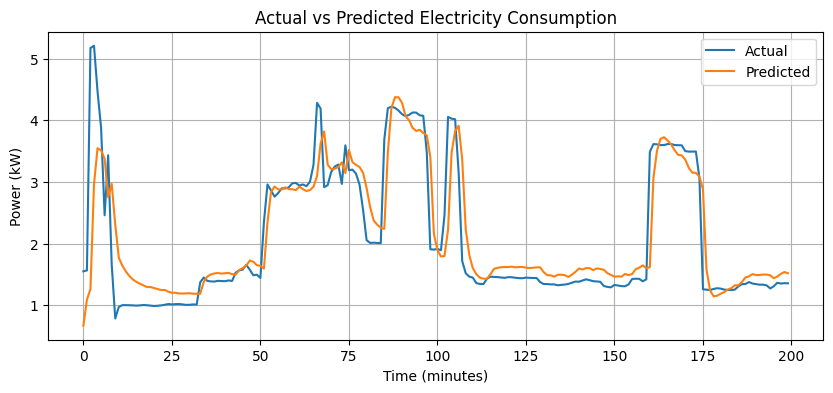

Next-minute forecast: 4.3591 kW


In [17]:

import matplotlib.pyplot as plt

# Plot actual and predicted consumption
plt.figure(figsize=(10, 4))
plt.plot(actual[:200], label="Actual")
plt.plot(predicted[:200], label="Predicted")
plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Time (minutes)")
plt.ylabel("Power (kW)")
plt.legend()
plt.grid()
plt.show()

# Forecast the next minute after the dataset
last = data[-60:].reshape(1, 60, 7)
next_value = model.predict(last, verbose=0)[0, 0]
forecast = (next_value - offset) / scale

print("Next-minute forecast:", round(float(forecast), 4), "kW")
